In [1]:
%load_ext autoreload
%autoreload 2

In [4]:
import sys
import warnings
warnings.simplefilter("ignore", UserWarning)

In [1]:
import torch
import os
import matplotlib.pyplot as plt
import random
from tqdm.auto import tqdm
import numpy as np
from torchvision import datasets, transforms
import torch.nn as nn
from torch.utils.data import Subset
import matplotlib.colors as mcolors

d:\anaconda3\envs\data-valuation-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
sys.path.insert(0, '.')
sys.path.append("..")
sys.path.append("../src")

from plot_utils import (
    plot_loss_acc,
    plot_train_val_loss_acc_separately,
    plot_loss_acc_difference,
    plot_var_acc_legends,
    plot_similar_indices,
    plot_cosine_similarity,
)

from utils import (
    random_p_data,
    concat_ckpt_metrics,
    create_influences_dict,
    top_last_influences,
    create_inf_int_distances,
    create_inter_entropies,
    create_inner_entropies,
    calc_pairwise_euclideans,
    calc_dist_inf_to_others,
    calc_volumes,
    pairwise_similarity,
    top_inf_indices,
    tsne_all_dataset,
    plt_decision_boundary,
    pw_cos_similarity,
)

from src.utils import load_checkpoint

In [6]:
dir_data="../data/"
dir_tensors = os.path.join("../influences/mnist", "mnist_2025-03-29_14-12-21")
dir_ckpt = "../checkpoint/"
dir_subset = os.path.join(dir_data,"subset_indices/mnist")
num_epochs = 100
ckpt_min = 1
ckpt_max = 100
p = 0.05
epochs_range = range(1, num_epochs + 1)
checkpoint_labels =  list([1, 2, 3, 5, 7, 10, 15, 20, 40, 60, 80, 100])

In [7]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.view(-1)) 
])
subset_indices = torch.load(f"{dir_subset}/train_subset_indices.pt")
mnist_train = datasets.MNIST(dir_data, train=True, download=False, transform=transform)
mnist_train = Subset(mnist_train, subset_indices)

In [8]:
save_objs_dict = torch.load(f"{dir_tensors}/accuracies_and_losses.pt", weights_only=False)

train_losses = save_objs_dict["model_eval_obj"].train_losses
validation_losses = save_objs_dict["model_eval_obj"].validation_losses
accuracies = save_objs_dict["model_eval_obj"].accuracies

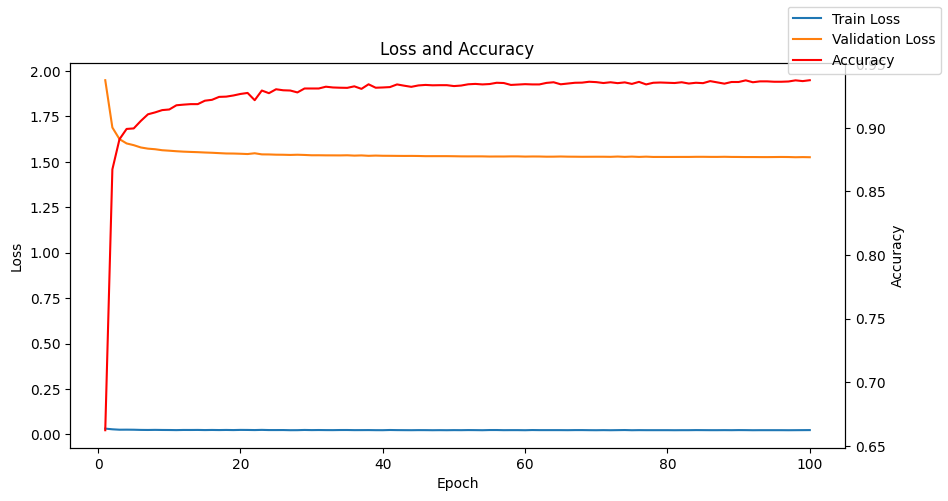

In [9]:
plot_loss_acc(epochs_range, train_losses, validation_losses, accuracies)

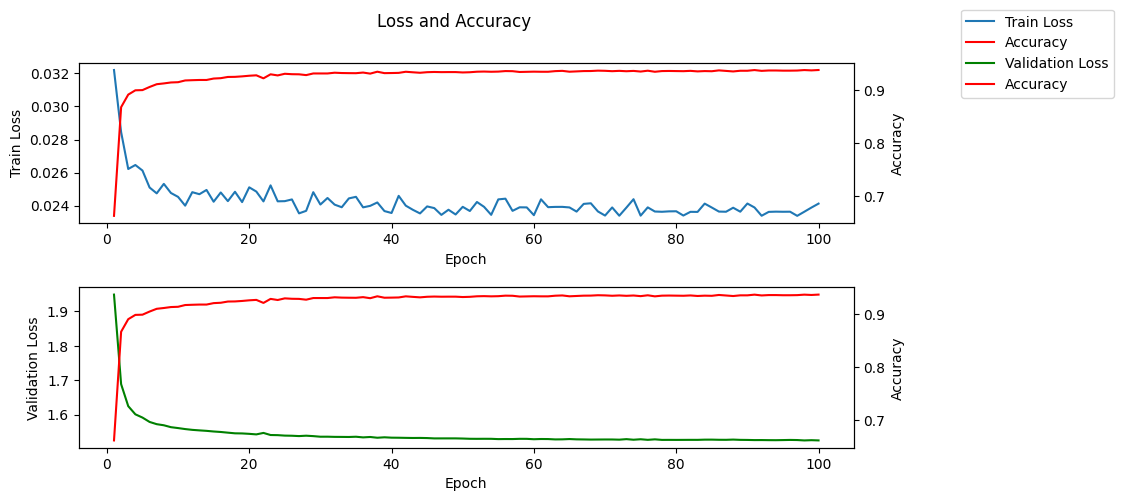

In [10]:
plot_train_val_loss_acc_separately(epochs_range, train_losses, validation_losses, accuracies)

# Influences

In [11]:
x_vals = list(range(1, num_epochs + 1))
num_data = len(mnist_train)
checkpoints_filepaths = [os.path.join(dir_ckpt, "DigitNet", f"DigitNet_epoch_{epoch}_{epoch/num_epochs}.pth") for epoch in checkpoint_labels]

mnist_influence_if = save_objs_dict["influences_if"]
# mnist_influence_tracin = save_objs_dict["influences_tracin"]
# mnist_influence_tmc_shapley = save_objs_dict["influences_tmc_shapley"]

scoring_methods = ["if"]
influences_methods = [mnist_influence_if]

validate_dict, rand_dict = create_influences_dict(save_objs_dict, checkpoint_labels, scoring_methods=scoring_methods)

In [12]:
p = 0.05
def generate_embed_dict(p):
    embeds_dict =  {}
    for i in range(len(scoring_methods)):
        the_random_embeds = random_p_data(influences_methods[i], mnist_train, num_data, p) 
        the_random_embeds_large = random_p_data(influences_methods[i], mnist_train, num_data, p*10)
        the_last_ckpts_embeds = top_last_influences(influences_methods[i], mnist_train, int(p*num_data), False) 
        the_top_ckpts_embeds = top_last_influences(influences_methods[i], mnist_train, int(num_data*p))

        embeds_dict[scoring_methods[i]] = {
            "random": the_random_embeds, 
            "random_large": the_random_embeds_large, 
            "last": the_last_ckpts_embeds, 
            "top": the_top_ckpts_embeds}
    return embeds_dict
embeds_dict = generate_embed_dict(0.05)

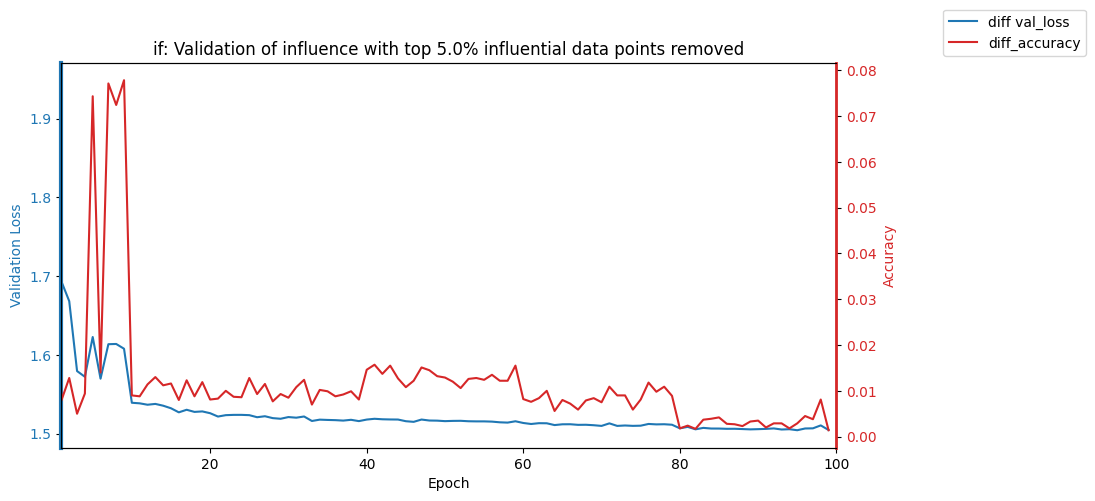

In [13]:
for scoring_method in scoring_methods:
    diff_val_loss = concat_ckpt_metrics(validate_dict[f"validate_validation_losses_{scoring_method}"], checkpoint_labels) - concat_ckpt_metrics(rand_dict[f"rand_validate_train_losses_{scoring_method}"], checkpoint_labels) # suppose positive
    diff_accuracy = concat_ckpt_metrics(rand_dict[f"rand_validate_accuracies_{scoring_method}"], checkpoint_labels) - concat_ckpt_metrics(validate_dict[f"validate_accuracies_{scoring_method}"], checkpoint_labels) # suppose positive
    plot_loss_acc_difference(diff_val_loss, diff_accuracy, scoring_method=f"{scoring_method}", p=p)

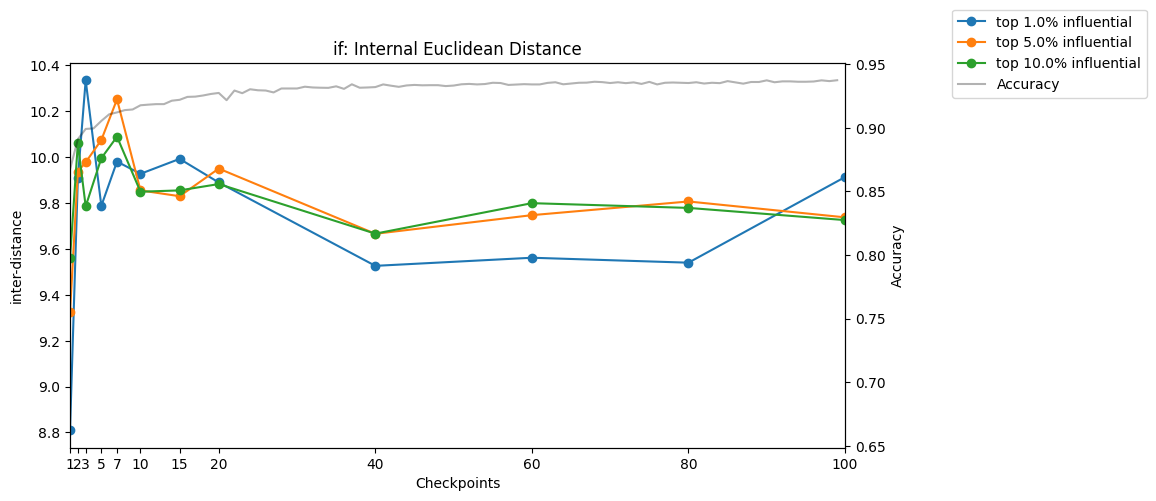

In [14]:
ls_p = [0.01, 0.05, 0.1]

for k in range(len(scoring_methods)):
    ls_int_distances = calc_pairwise_euclideans(influences_methods[k], mnist_train, ls_p)
    kwargs = {
        "title": f"{scoring_methods[k]}: Internal Euclidean Distance",
        "y_label": "inter-distance",
        "data": ls_int_distances,
        "legend_labels": [f"top {prob*100}% influential" for prob in ls_p]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

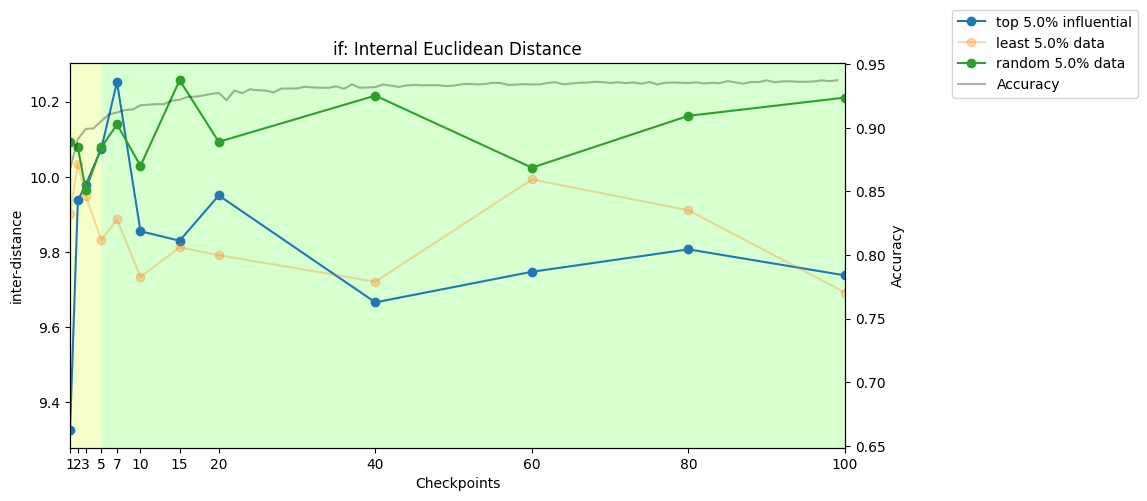

In [14]:
p = 0.05
# p = 0.1
embeds_dict = generate_embed_dict(p)
for k in range(len(scoring_methods)):
    topinf_int_distances = create_inf_int_distances(embeds_dict[scoring_methods[k]]["top"])
    lastinf_int_distances = create_inf_int_distances(embeds_dict[scoring_methods[k]]["last"])
    rand_int_distances = create_inf_int_distances(embeds_dict[scoring_methods[k]]["random"])
    randlarge_int_distances = create_inf_int_distances(embeds_dict[scoring_methods[k]]["random_large"])

    kwargs = {
        "title": f"{scoring_methods[k]}: Internal Euclidean Distance",
        "y_label": "inter-distance",
        "data": [topinf_int_distances, lastinf_int_distances, rand_int_distances],
        "legend_labels": [f"top {p*100}% influential", f"least {p*100}% data", f"random {p*100}% data"],
        "highlight_regions": [(1, 5), (5, 100)]
    }
    
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

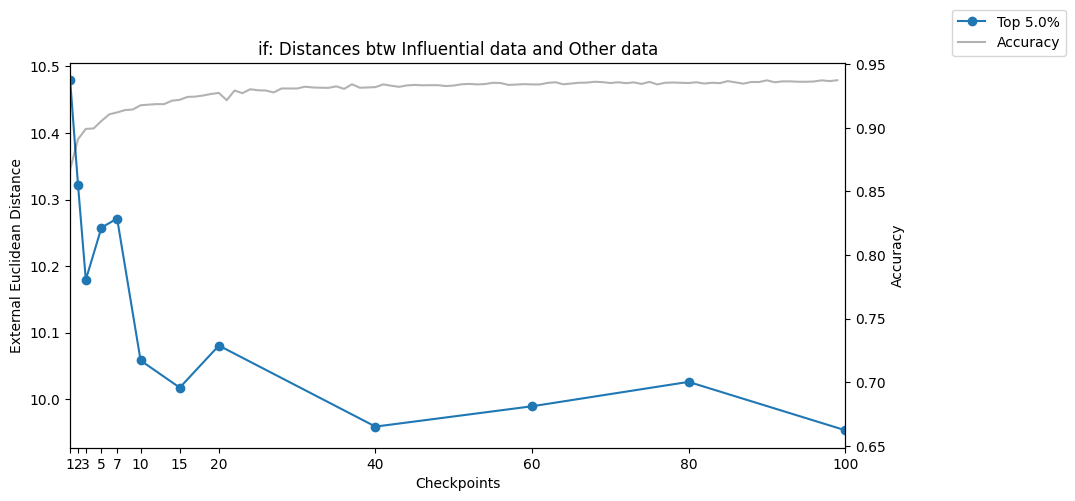

In [15]:
# Euclidean distance from influential points to other points
for k in range(len(scoring_methods)):
    distances = calc_dist_inf_to_others(select_inf_embeds = embeds_dict[scoring_methods[k]]["top"], 
                                        other_inf_embeds = embeds_dict[scoring_methods[k]]["random_large"])

    kwargs = {
        "title": f"{scoring_methods[k]}: Distances btw Influential data and Other data",
        "y_label": "External Euclidean Distance",
        "data": [distances],
        "legend_labels": [f"Top {p*100}%"]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

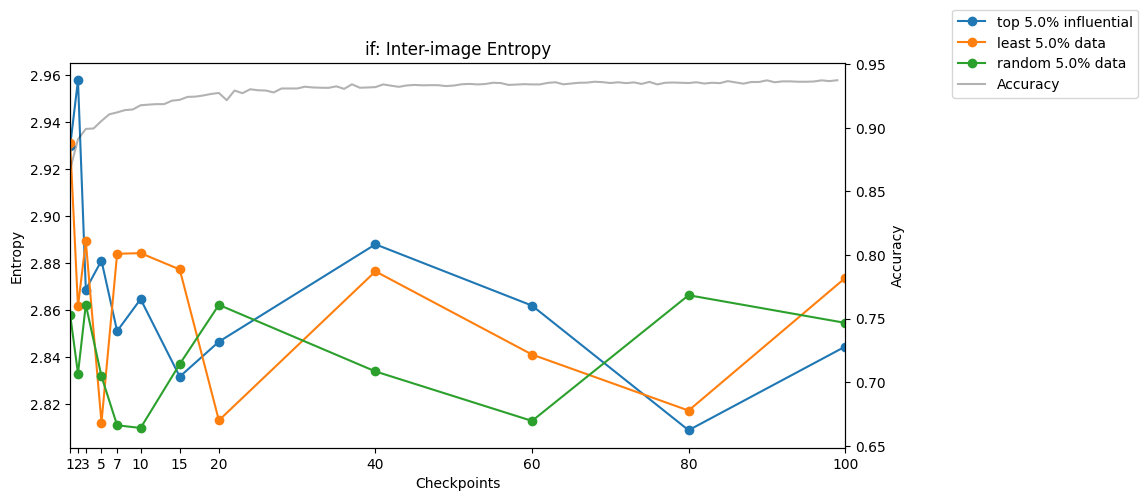

In [16]:
for k in range(len(scoring_methods)):
    topinf_entropies = create_inter_entropies(embeds_dict[scoring_methods[k]]["top"])
    lastinf_pw_entropies = create_inter_entropies(embeds_dict[scoring_methods[k]]["last"])
    rand_pw_entropies = create_inter_entropies(embeds_dict[scoring_methods[k]]["random"])
    rand_pw_large_entropies = create_inter_entropies(embeds_dict[scoring_methods[k]]["random_large"])
    
    kwargs = {
        "title": f"{scoring_methods[k]}: Inter-image Entropy",
        "y_label": "Entropy",
        "data": [topinf_entropies, lastinf_pw_entropies, rand_pw_entropies],
        "legend_labels": [f"top {p*100}% influential", f"least {p*100}% data", f"random {p*100}% data"]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

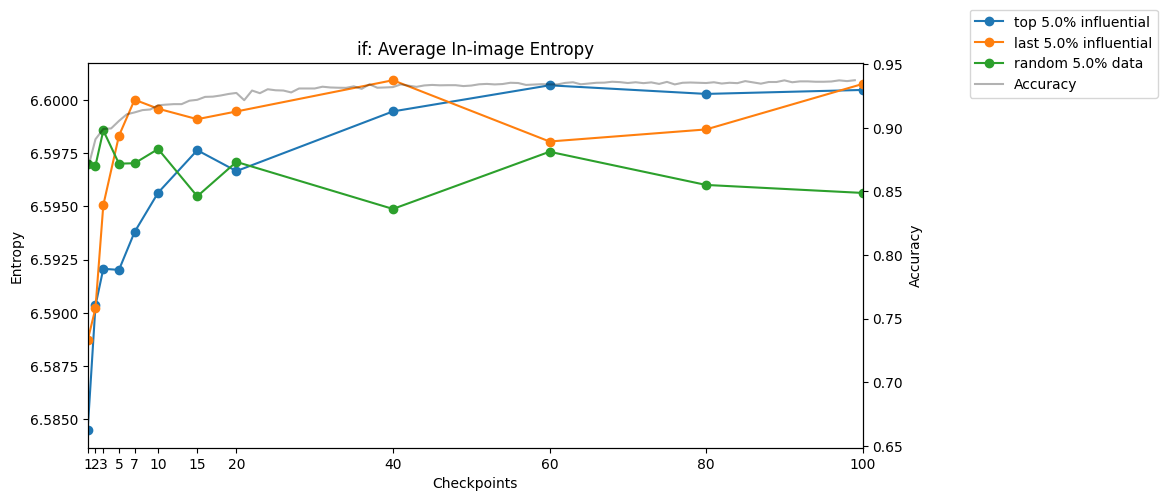

In [17]:
for k in range(len(scoring_methods)):
    topinf_entropies = create_inner_entropies(embeds_dict[scoring_methods[k]]["top"])
    lastinf_pw_entropies = create_inner_entropies(embeds_dict[scoring_methods[k]]["last"])
    rand_pw_entropies = create_inner_entropies(embeds_dict[scoring_methods[k]]["random"])
    rand_pw_large_entropies = create_inner_entropies(embeds_dict[scoring_methods[k]]["random_large"])

    kwargs = {
        "title": f"{scoring_methods[k]}: Average In-image Entropy",
        "y_label": "Entropy",
        "data": [topinf_entropies, lastinf_pw_entropies, rand_pw_entropies],
        "legend_labels": [f"top {p*100}% influential", f"last {p*100}% influential", f"random {p*100}% data", f"random {p*100*10}% data"]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

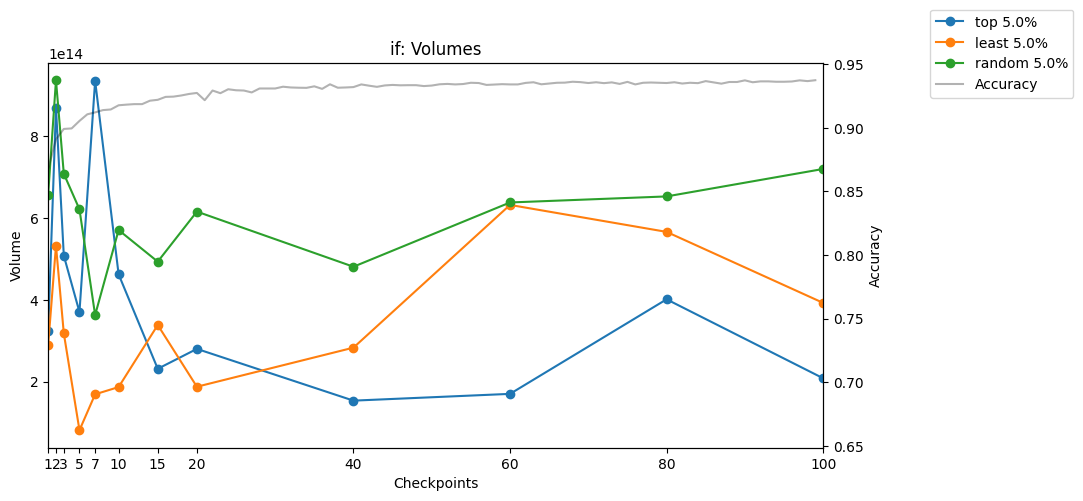

In [15]:
labels = ["top", "least", "random"]

for k in range(len(scoring_methods)):
    ls_volumes = calc_volumes([embeds_dict[scoring_methods[k]]["top"], embeds_dict[scoring_methods[k]]["last"], embeds_dict[scoring_methods[k]]["random"]])
    kwargs = {
        "title": f"{scoring_methods[k]}: Volumes",
        "y_label": "Volume",
        "data": ls_volumes,
        "legend_labels": [f"{label} {p*100}%" for label in labels],
        # "highlight_regions": [(1, 7), (7, 100)]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

# Loss and Accuracy

In [19]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device: ", device)

Device:  cpu


In [20]:
class DigitNet(nn.Module):
    def __init__(self, input_dimensions=784, num_classes=10): 
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dimensions, 512),
            nn.ReLU(),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
            nn.Softmax(dim=-1)
            )
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.model(x)

In [21]:
def plot_get_losses(ls_embeds, legend_labels, losses):
    fig, ax1 = plt.subplots(figsize=(10, 5))
    ax1.set_xlim(min(x_vals), max(x_vals))
    for j, ckpts_embeds in enumerate(ls_embeds):
        train_losses = [] # CrossEntropy loss
        for i, embeds in enumerate(ckpts_embeds):
            checkpoint = checkpoints_filepaths[i]
            inputs = torch.tensor(np.array([embed[0] for embed in embeds]), dtype=torch.float32, device=device)
            expect_val = torch.tensor([embed[1] for embed in embeds], device=device)
            optimizer = torch.optim.Adam(DigitNet().parameters(), lr=0.0001)
            # print(f"Loading checkpoint {checkpoint}")
            model, optimizer, _, _ = load_checkpoint(DigitNet().to(device), optimizer, checkpoint)
            loss_fn = nn.CrossEntropyLoss()
            outputs = model(inputs)
            loss = loss_fn(outputs, expect_val)
            train_losses.append(loss.item())
        ax1.plot(checkpoint_labels, train_losses, 'o-', 
                label=f"{legend_labels[j]} {p*100}% train loss")

    plt.title("Train loss (CrossEntropyLoss)")
    ax1.set_xlabel("Checkpoint")
    ax1.set_ylabel("Loss")
    ax1.set_xticks(checkpoint_labels)
    ax1.plot(losses, label="train loss", color='k')

    fig.legend(loc='upper left', bbox_to_anchor=(1,1))
    plt.show()

def plot_get_accs(ls_embeds, legend_labels, train_accuracies):
    fig, ax1 = plt.subplots(figsize=(10, 5))
    ax1.set_xlim(min(x_vals), max(x_vals))

    for j, ckpts_embeds in enumerate(ls_embeds):
        accuracies = []
        
        for i, embeds in enumerate(ckpts_embeds):
            checkpoint = checkpoints_filepaths[i]
            inputs = torch.tensor(np.array([embed[0] for embed in embeds]), dtype=torch.float32, device=device)
            expect_val = torch.tensor([embed[1] for embed in embeds], device=device)
            optimizer = torch.optim.Adam(DigitNet().parameters(), lr=0.0001)
            model, optimizer, _, _ = load_checkpoint(DigitNet().to(device), optimizer, checkpoint)
            outputs = model(inputs)
            predictions = torch.argmax(outputs, dim=-1)
            accuracy = (predictions == expect_val).int().sum() / len(expect_val)
            accuracies.append(accuracy.cpu())
        ax1.plot(checkpoint_labels, accuracies, 'o-', 
                label=f"{legend_labels[j]} {p*100}% accuracy")

    plt.title("Training data accuracy")
    ax1.set_xlabel("Checkpoint")
    ax1.set_ylabel("Accuracy")
    ax1.set_xticks(checkpoint_labels)
    ax1.plot(train_accuracies, label="Accuracy", color='k')

    fig.legend(loc='upper left', bbox_to_anchor=(1,1))
    plt.show()
    
# contribute to final model？
def plot_get_final_accs(ls_embeds, legend_labels, train_accuracies):
    fig, ax1 = plt.subplots(figsize=(10, 5))
    ax1.set_xlim(min(x_vals), max(x_vals))
    optimizer = torch.optim.Adam(DigitNet().parameters(), lr=0.0001)
    model, optimizer, _, _ = load_checkpoint(DigitNet().to(device), optimizer, checkpoints_filepaths[-1])

    for j, ckpts_embeds in enumerate(ls_embeds):
        accuracies = []
        for i, embeds in enumerate(ckpts_embeds):
            inputs = torch.tensor(np.array([embed[0] for embed in embeds]), dtype=torch.float32, device=device)
            expect_val = torch.tensor([embed[1] for embed in embeds], device=device)
            outputs = model(inputs)
            predictions = torch.argmax(outputs, dim=-1)
            accuracy = (predictions == expect_val).int().sum() / len(expect_val)
            accuracies.append(accuracy.cpu())
        ax1.plot(checkpoint_labels, accuracies, 'o-', 
                label=f"{legend_labels[j]} {p*100}% accuracy")

    plt.title("Training data accuracy of final model")
    ax1.set_xlabel("Checkpoint")
    ax1.set_ylabel("Accuracy")
    ax1.set_xticks(checkpoint_labels)
    ax1.plot(train_accuracies, label="Accuracy", color='k')

    fig.legend(loc='upper left', bbox_to_anchor=(1,1))
    plt.show()

## For IF

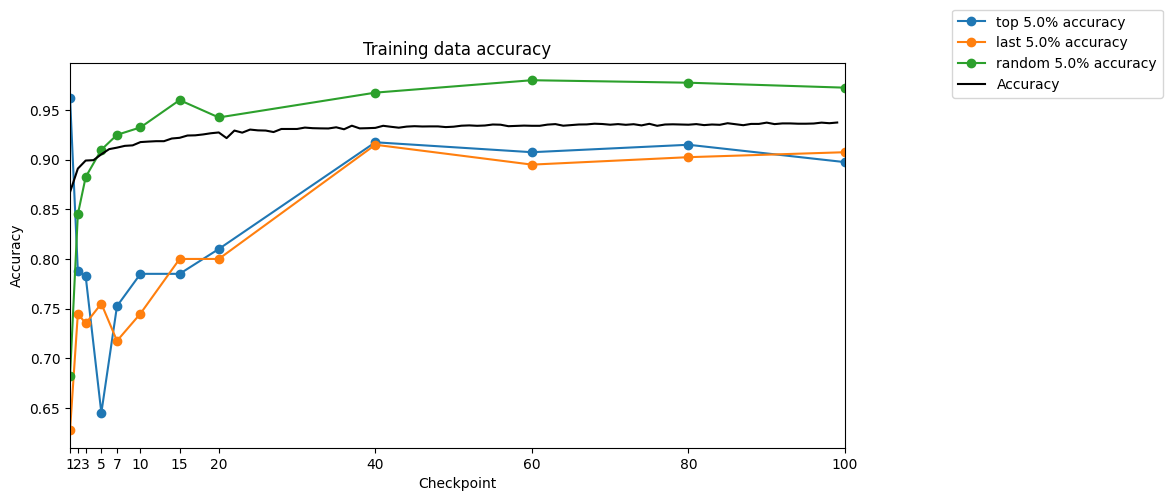

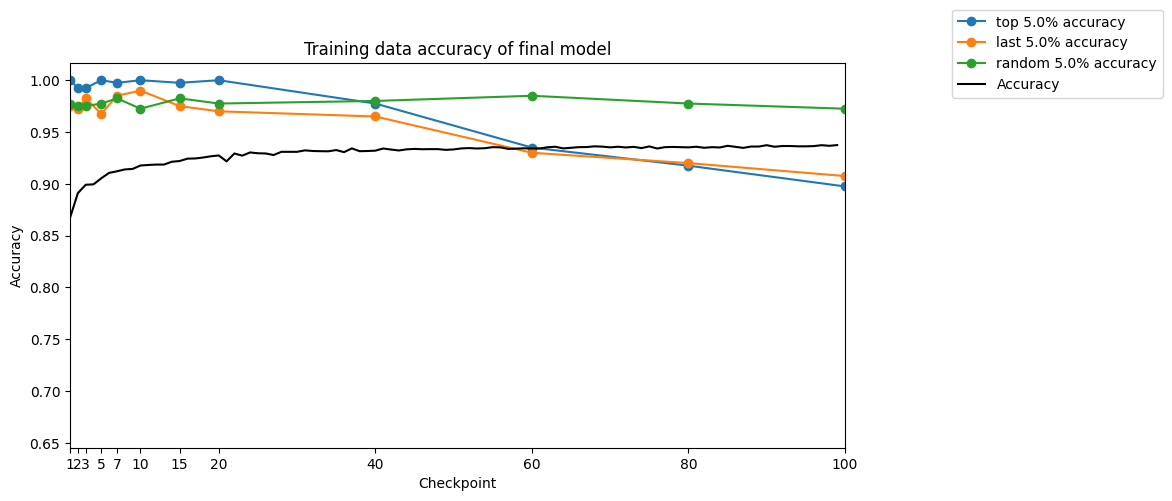

In [22]:
p = 0.05
# p = 0.1
embeds_dict = generate_embed_dict(p)

labels = ["top", "last", "random"]
ls_embeds = [embeds_dict["if"]["top"],
             embeds_dict["if"]["last"],
             embeds_dict["if"]["random"]]
# plot_get_losses(ls_embeds, labels, train_losses)
plot_get_accs(ls_embeds, labels, accuracies)
plot_get_final_accs(ls_embeds, labels, accuracies)

## For TracIn

In [23]:
labels = ["top", "last", "random"]
ls_embeds = [embeds_dict["tracin"]["top"],
             embeds_dict["tracin"]["last"],
             embeds_dict["tracin"]["random"]]
plot_get_losses(ls_embeds, labels, train_losses)
plot_get_accs(ls_embeds, labels, accuracies)

KeyError: 'tracin'

In [ ]:
# Least influtial points qualitative check
def plot_img(embeds, num_cols=10):
    fig, ax = plt.subplots(len(embeds), 10, figsize=(20, 20))
    for i in range(len(embeds)):
        for j in range(num_cols):
            ax[i, j].imshow(embeds[i][j][0].reshape(28, 28))
            ax[i, j].axis('off')
            ax[i, j].set_title(f"Label: {embeds[i][j][1]}")
    plt.tight_layout()
    plt.show()

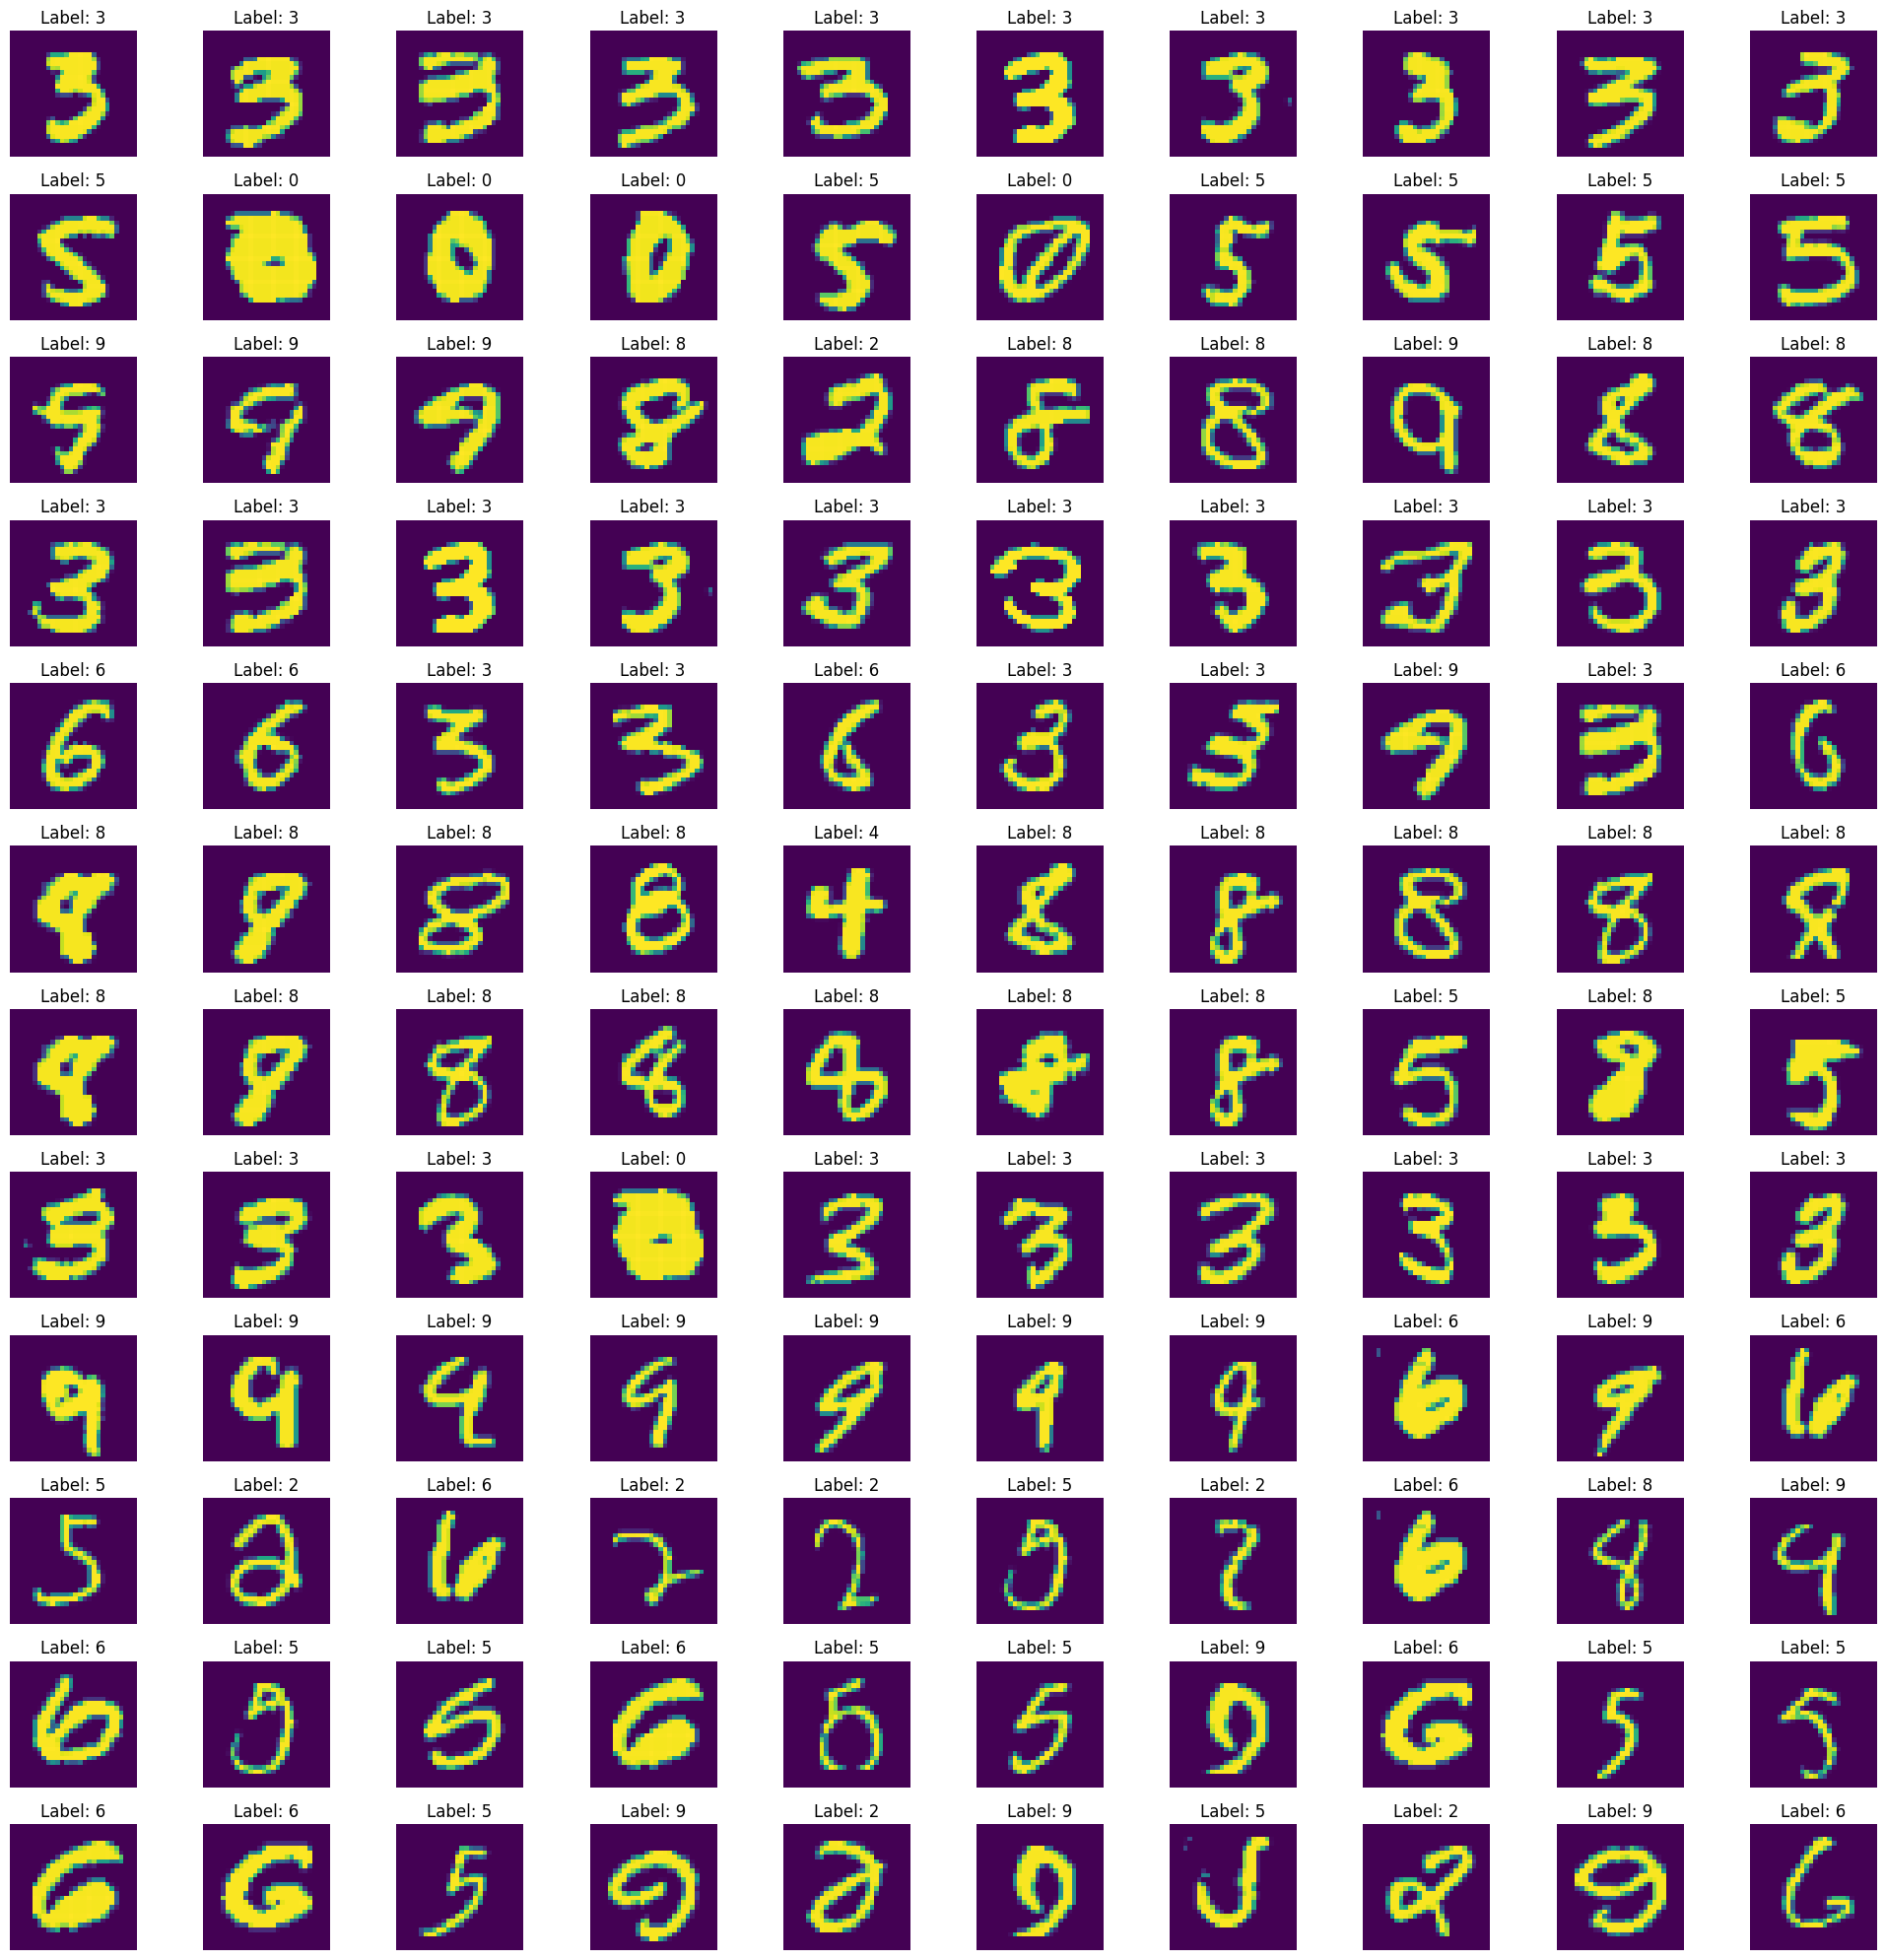

In [ ]:
plot_img(embeds_dict["if"]["top"])

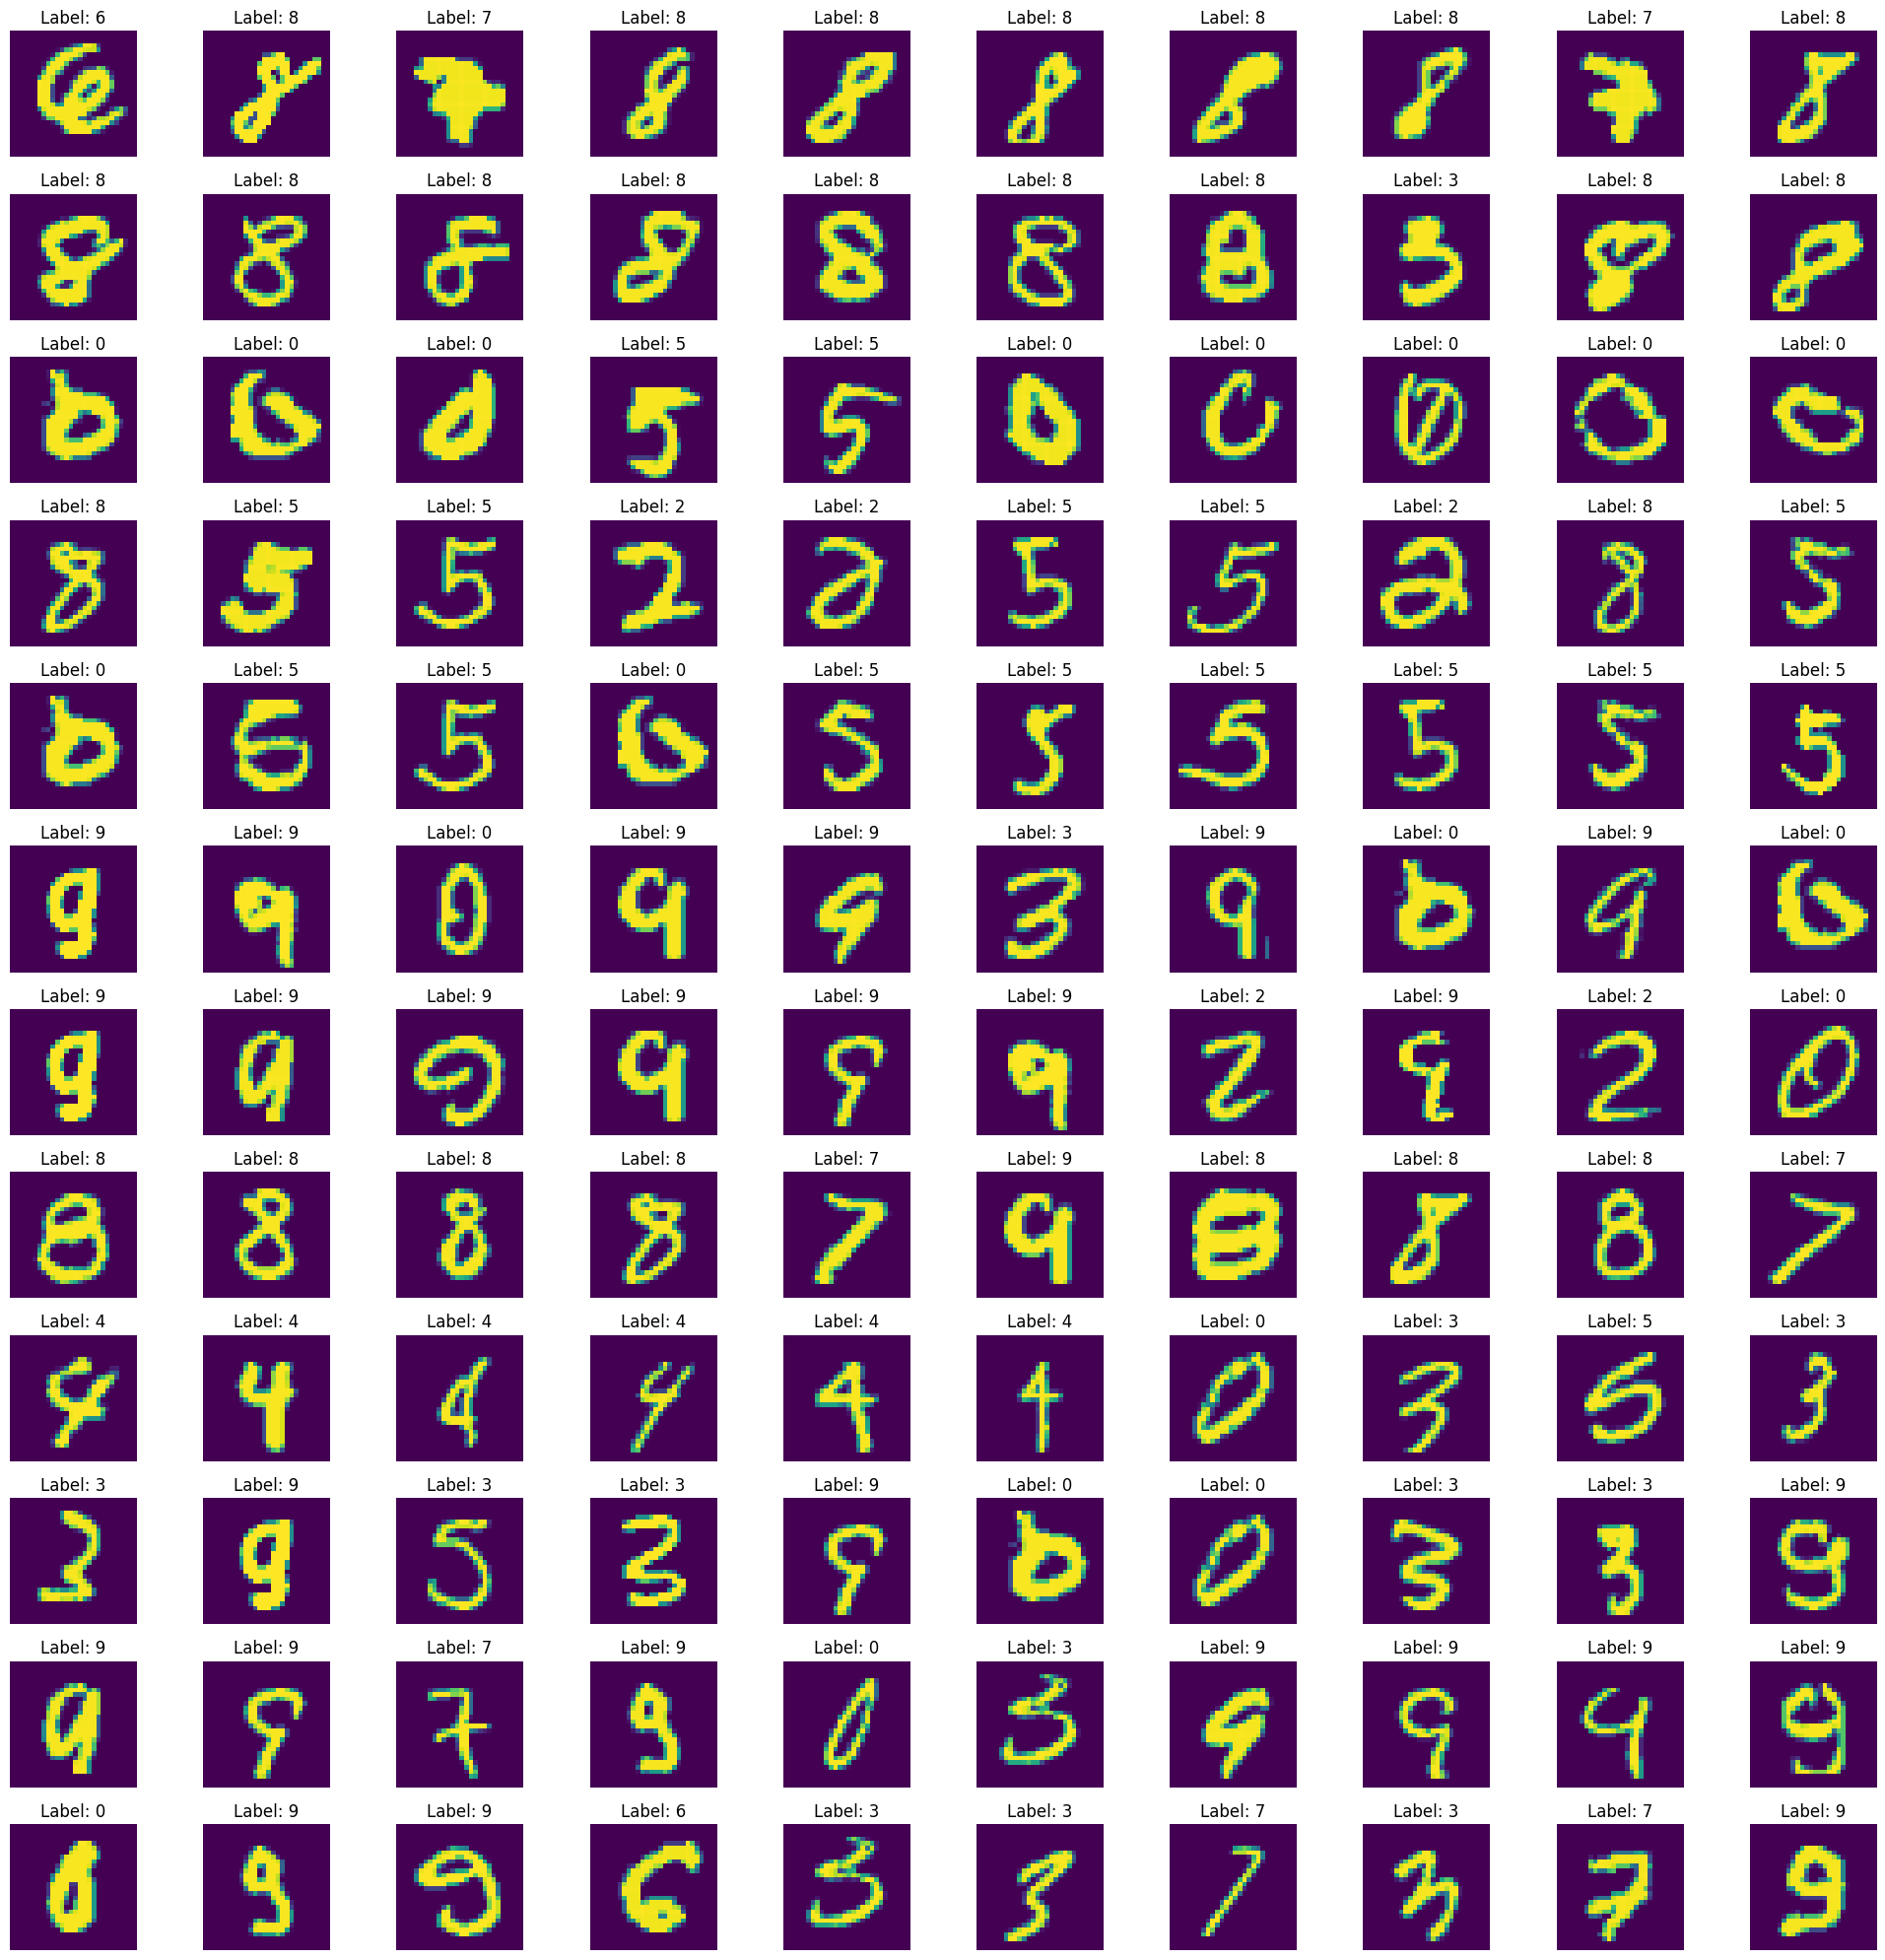

In [ ]:
plot_img(embeds_dict["if"]["last"])

In [ ]:
plot_img(embeds_dict["tracin"]["top"])

In [ ]:
plot_img(embeds_dict["tracin"]["last"])

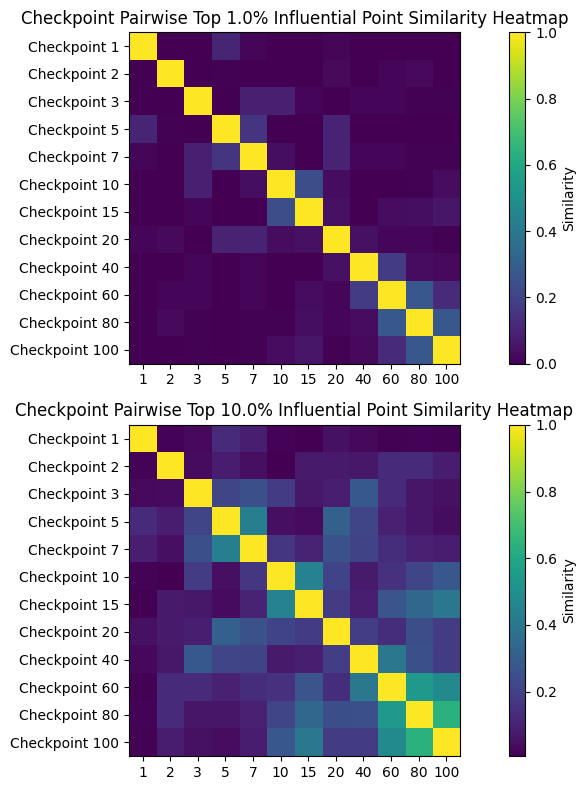

In [ ]:
for k in range(len(scoring_methods)):
    pw_similarities_lowp = pairwise_similarity(top_inf_indices(influences_methods[k], int(p*num_data)))
    pw_similarities_highp = pairwise_similarity(top_inf_indices(influences_methods[k], int(0.1*num_data)))

    plot_similar_indices(pw_similarities_lowp, pw_similarities_highp, checkpoint_labels, p)

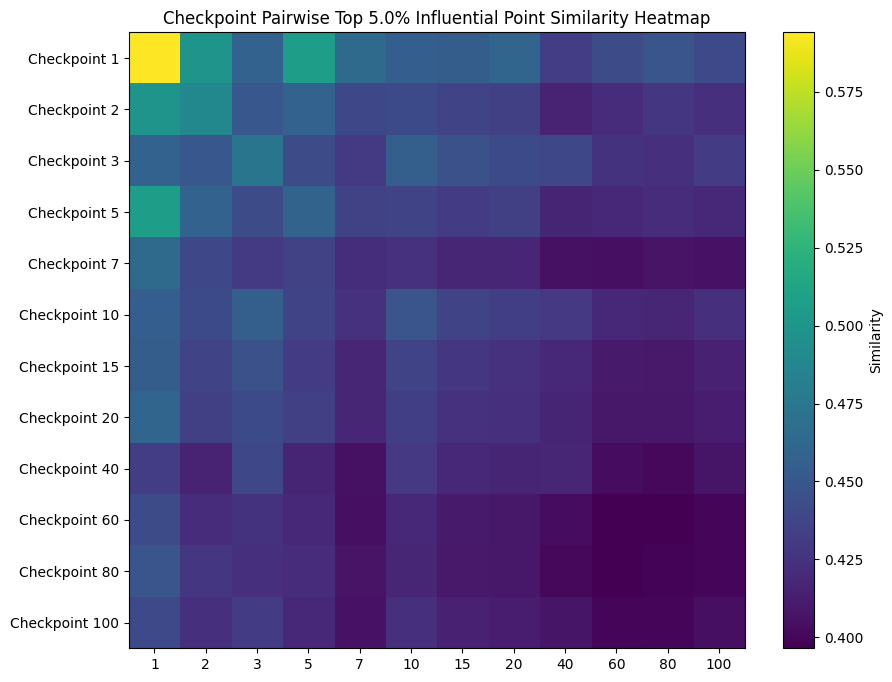

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
p = 0.05
ckpts_embeds = generate_embed_dict(p)

for k in range(len(influences_methods)):
    topinf_similarities = pw_cos_similarity(embeds_dict["if"]["top"])
    # lastinf_similarities = pw_cos_similarity(influences_methods["if"]["last"], int(0.1*num_data))
    plot_cosine_similarity(topinf_similarities, checkpoint_labels, p)

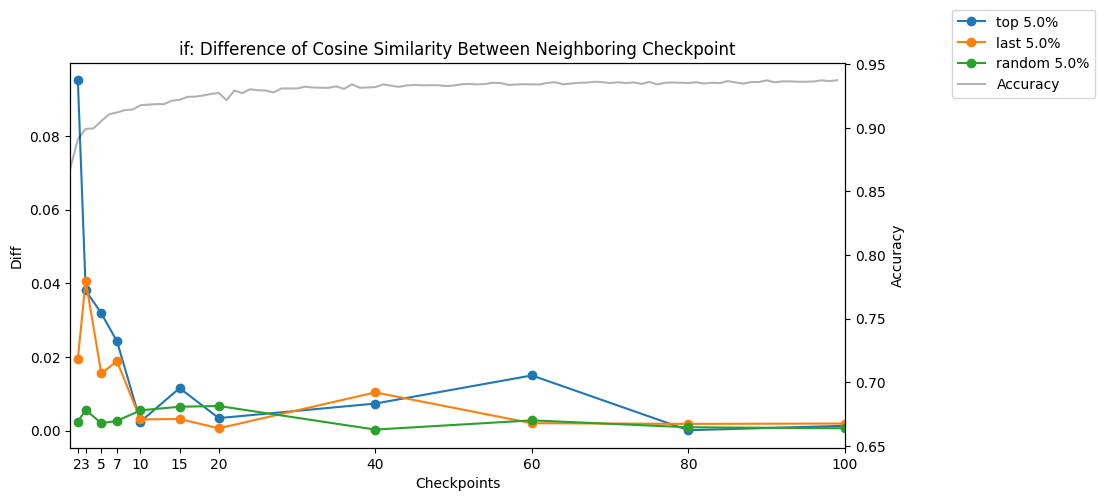

In [ ]:
p = 0.05
ckpts_embeds = generate_embed_dict(p)
for k in range(len(scoring_methods)):
    topinf_similarities = pw_cos_similarity(embeds_dict[f"{scoring_methods[k]}"]["top"])
    similarity_diff_top = [np.abs(topinf_similarities[i][i] - topinf_similarities[i][i+1]) for i in range(len(checkpoint_labels)-1)]
    
    leastinf_similarities = pw_cos_similarity(embeds_dict[f"{scoring_methods[k]}"]["last"])
    similarity_diff_least = [np.abs(leastinf_similarities[i][i] - leastinf_similarities[i][i+1]) for i in range(len(checkpoint_labels)-1)]
    
    randinf_similarities = pw_cos_similarity(embeds_dict[f"{scoring_methods[k]}"]["random"])
    similarity_diff_rand = [np.abs(randinf_similarities[i][i] - randinf_similarities[i][i+1]) for i in range(len(checkpoint_labels)-1)]
    
    kwargs = {
        "title": f"{scoring_methods[0]}: Difference of Cosine Similarity Between Neighboring Checkpoint",
        "y_label": "Diff",
        "data": [similarity_diff_top, similarity_diff_least, similarity_diff_rand],
        "legend_labels": [f"{label} {p*100}%" for label in labels],
    }
    plot_var_acc_legends(x_vals, checkpoint_labels[1:], accuracies, **kwargs)

# Decision Boundary

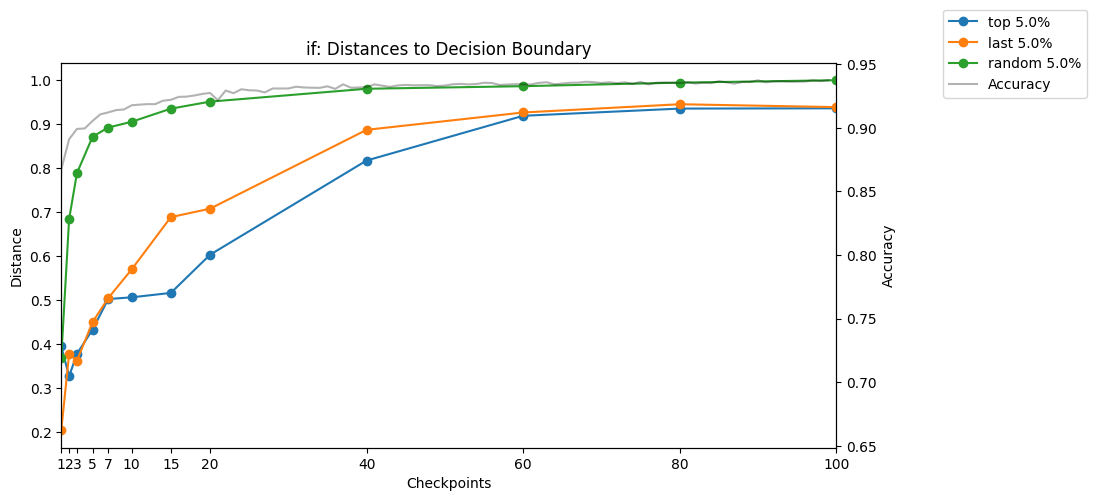

In [ ]:
optimizer = torch.optim.Adam(DigitNet().parameters(), lr=0.0001)
for i in range(len(scoring_methods)):
    dist_lst = []
    for j, ckpts_embeds in enumerate([embeds_dict[scoring_methods[i]]["top"], embeds_dict[scoring_methods[i]]["last"], embeds_dict[scoring_methods[i]]["random"]]):
        distance_to_dec_boundary = []
        
        for k, embeds in enumerate(ckpts_embeds):
            checkpoint = checkpoints_filepaths[k]
            inputs = torch.tensor(np.array([embed[0] for embed in embeds]), dtype=torch.float32, device=device)
            model, optimizer, _, _ = load_checkpoint(DigitNet().to(device), optimizer, checkpoint)
            outputs = model(inputs)
            top_logits = torch.sort(outputs, descending=True, dim=-1).values
            distances = torch.mean(top_logits[:, 0] - top_logits[:, 1])
            distance_to_dec_boundary.append(distances.item())
        dist_lst.append(distance_to_dec_boundary)
    kwargs = {
        "title": f"{scoring_methods[i]}: Distances to Decision Boundary",
        "y_label": "Distance",
        "data": dist_lst,
        "legend_labels": [f"{label} {p*100}%" for label in labels]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

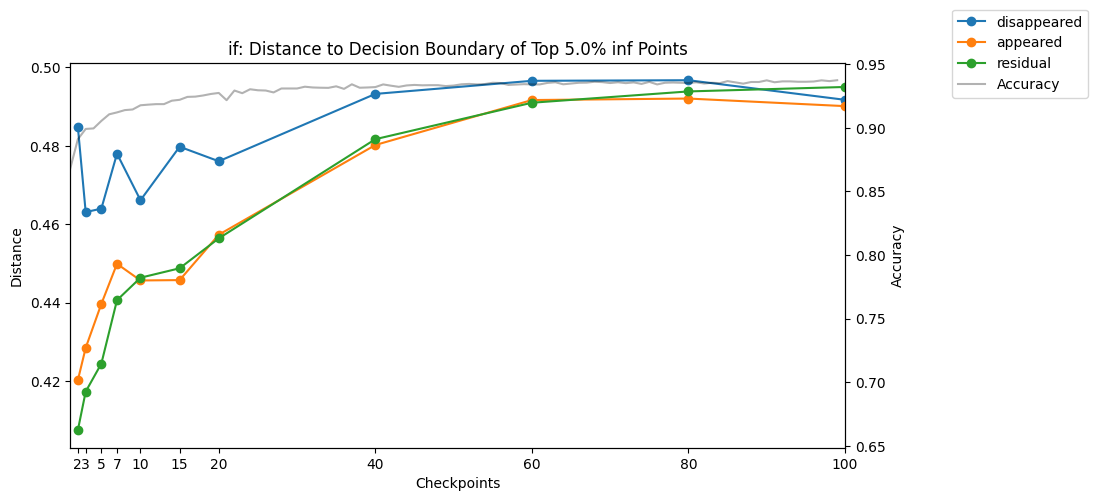

In [ ]:
topinf_indexes = top_inf_indices(mnist_influence_if, int(p*num_data))
def generate_dist_to_decision_boundary(model, dataset):
    inputs = torch.tensor(np.array([data[0] for data in dataset]))
    outputs = model(inputs.to(device))
    distance_to_dec_boundary = torch.mean(torch.abs(outputs - 0.5))
    return distance_to_dec_boundary

disappeared_distances = []
appeared_distances = []
residual_distances = []

for i in range(1, len(topinf_indexes)):
    checkpoint = checkpoints_filepaths[i]
    optimizer = torch.optim.Adam(DigitNet().parameters(), lr=1e-4)
    model, _, _, _ = load_checkpoint(DigitNet().to(device), optimizer, checkpoint)
    
    disappear_topinf_indices = set(topinf_indexes[i-1]).difference(set(topinf_indexes[i]))
    disappear_subset = Subset(mnist_train, list(disappear_topinf_indices))
    disappear_dist = generate_dist_to_decision_boundary(model, disappear_subset).detach().numpy()
    disappeared_distances.append(disappear_dist)
    
    newly_appeared_indices = set(topinf_indexes[i]).difference(set(topinf_indexes[i-1]))
    appeared_subset = Subset(mnist_train, list(newly_appeared_indices))
    appeared_dist = generate_dist_to_decision_boundary(model, appeared_subset).detach().numpy()
    appeared_distances.append(appeared_dist)
    
    residual_indices = set(topinf_indexes[i]).intersection(set(topinf_indexes[i-1]))
    residual_subset = Subset(mnist_train, list(residual_indices))
    residual_dist = generate_dist_to_decision_boundary(model, residual_subset).detach().numpy()
    residual_distances.append(residual_dist)

kwargs = {
    "data": [disappeared_distances, appeared_distances, residual_distances],
    "title": f"if: Distance to Decision Boundary of Top {p*100}% inf Points",
    "y_label": "Distance",
    "legend_labels": ["disappeared", "appeared", "residual"]
}

plot_var_acc_legends(x_vals, checkpoint_labels[1:], accuracies, **kwargs)

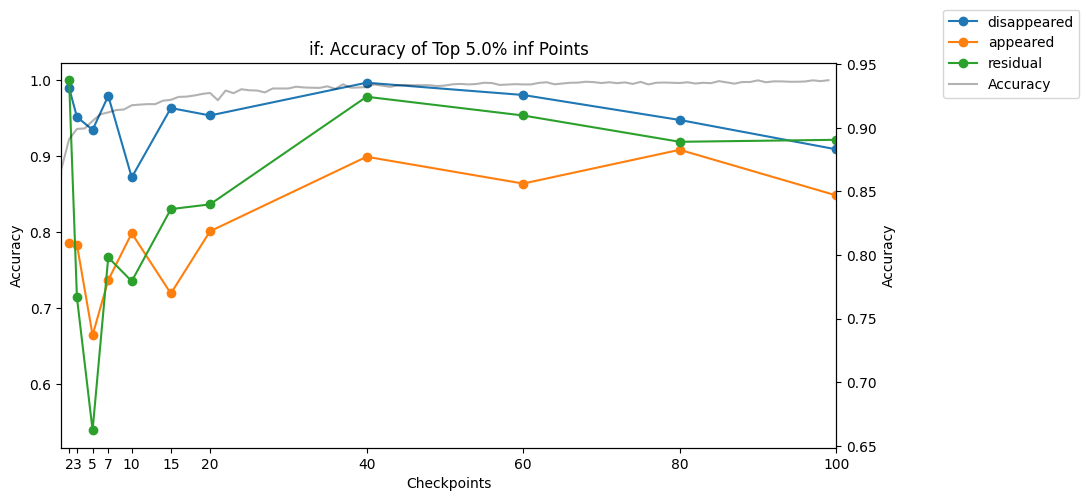

In [ ]:
topinf_indexes = top_inf_indices(mnist_influence_if, int(p*num_data))
def compute_accuracy(model, dataset):
    inputs = torch.tensor(np.array([data[0] for data in dataset]))
    outputs = model(inputs.to(device))
    predictions = torch.argmax(outputs, dim=-1)
    expect_val = torch.tensor([data[1] for data in dataset], device=device)
    accuracy = (predictions == expect_val).sum() / len(expect_val)
    return accuracy

disappeared_accuracies = []
appeared_accuracies = []
residual_accuracies = []

for i in range(1, len(topinf_indexes)):
    checkpoint = checkpoints_filepaths[i]
    optimizer = torch.optim.Adam(DigitNet().parameters(), lr=1e-4)
    model, _, _, _ = load_checkpoint(DigitNet().to(device), optimizer, checkpoint)
    
    disappear_topinf_indices = set(topinf_indexes[i-1]).difference(set(topinf_indexes[i]))
    disappear_subset = Subset(mnist_train, list(disappear_topinf_indices))
    disappear_accuracy = compute_accuracy(model, disappear_subset)
    disappeared_accuracies.append(disappear_accuracy)
    
    newly_appeared_indices = set(topinf_indexes[i]).difference(topinf_indexes[i-1])
    appeared_subset = Subset(mnist_train, list(newly_appeared_indices))
    appeared_accuracy = compute_accuracy(model, appeared_subset)
    appeared_accuracies.append(appeared_accuracy)
    
    residual_indices = set(topinf_indexes[i]).intersection(topinf_indexes[i-1])
    residual_subset = Subset(mnist_train, list(residual_indices))
    residual_accuracy = compute_accuracy(model, residual_subset)
    residual_accuracies.append(residual_accuracy)

kwargs = {
    "data": [disappeared_accuracies, appeared_accuracies, residual_accuracies],
    "title": f"if: Accuracy of Top {p*100}% inf Points",
    "y_label": "Accuracy",
    "legend_labels": ["disappeared", "appeared", "residual"]
}

plot_var_acc_legends(x_vals, checkpoint_labels[1:], accuracies, **kwargs)


In [ ]:
def filter_dataset(label1, label2, ckpts_influences):
    targets = mnist_train.dataset.targets[mnist_train.indices]
    mask = (targets == label1) | (targets == label2)
    filtered_indices = subset_indices[mask]
    filtered_influences = [influences[mask] for influences in ckpts_influences]
    filtered_dataset = Subset(mnist_train.dataset, filtered_indices)
    return filtered_dataset, filtered_influences

Plotting Decision Boundary: 100%|██████████| 12/12 [00:02<00:00,  5.19it/s]


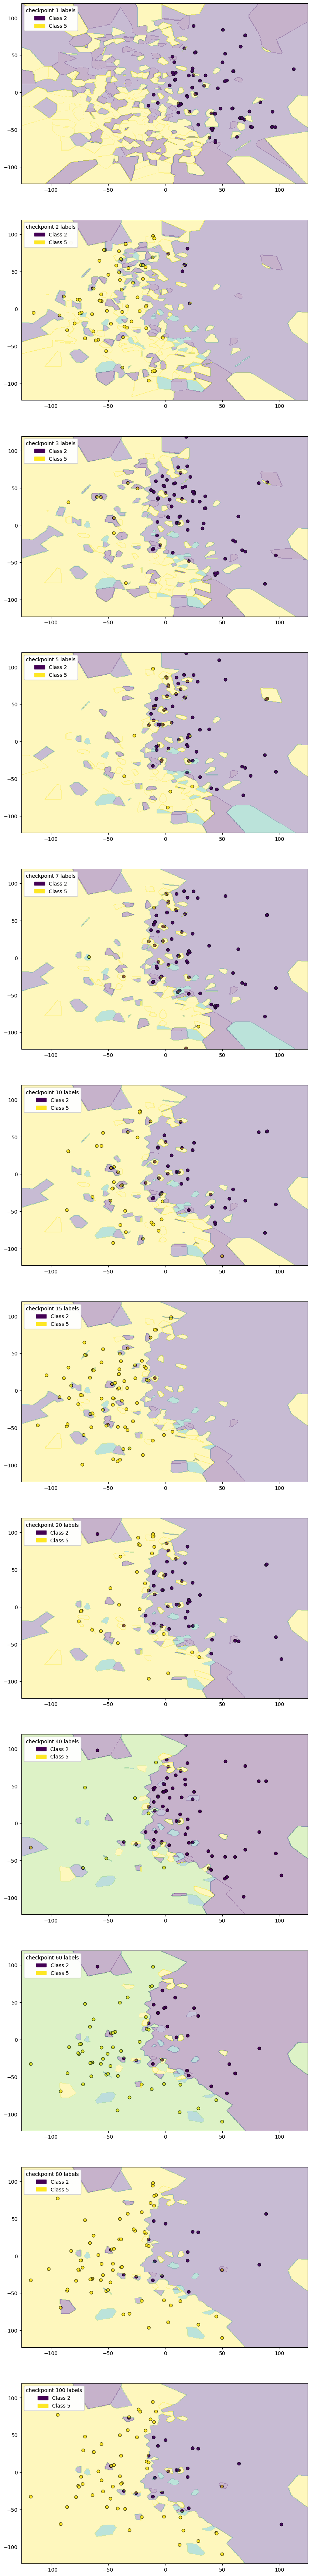

In [ ]:
p = 0.01
filtered_dataset, filtered_influences = filter_dataset(2, 5, mnist_influence_if)
for k in range(len(scoring_methods)):
    ckpts_top_inf_indices = top_inf_indices(filtered_influences, int(p*num_data))
    all_x_2d, all_data_y, all_data_x = tsne_all_dataset(filtered_dataset)
    fig, ax = plt.subplots(len(checkpoint_labels), 1, figsize=(10, 90))
    unique_labels = torch.unique(torch.tensor([label for _, label in filtered_dataset]))
    min_label, max_label = unique_labels.min().item(), unique_labels.max().item()

    custom_cmap = plt.get_cmap('viridis')
    norm = mcolors.Normalize(vmin=min_label, vmax=max_label)
    # custom_cmap = plt.get_cmap('tab10')
    # norm = mcolors.Normalize(vmin=0, vmax=9)
    for k, ckpt_top_inf_indices in tqdm(enumerate(ckpts_top_inf_indices), desc='Plotting Decision Boundary', total=len(checkpoint_labels)):
        model, _, _, _ = load_checkpoint(DigitNet().to(device), torch.optim.Adam(DigitNet().parameters(), lr=0.0001), checkpoints_filepaths[k])
        output = model(torch.tensor(all_data_x, dtype=torch.float32, device=device))
        all_y_pred = torch.argmax(output, dim=-1).flatten()
        plt_decision_boundary(ckpt_top_inf_indices, checkpoint_labels, all_x_2d, all_data_y, all_y_pred, ax[k], k, custom_cmap, norm, unique_labels)
    # fig.tight_layout()
    plt.show()